In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [3]:
df = pd.read_csv("car.csv")

In [4]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000.0,70000.0,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000.0,50000.0,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000.0,100000.0,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000.0,46000.0,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000.0,141000.0,Diesel,Individual,Manual,Second Owner


In [5]:
df = df.drop("name", axis = 1)

In [6]:
df

,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,2007,60000.0,70000.0,Petrol,Individual,Manual,First Owner
1,2007,135000.0,50000.0,Petrol,Individual,Manual,First Owner
2,2012,600000.0,100000.0,Diesel,Individual,Manual,First Owner
3,2017,250000.0,46000.0,Petrol,Individual,Manual,First Owner
4,2014,450000.0,141000.0,Diesel,Individual,Manual,Second Owner
...,...,...,...,...,...,...,...
4335,2014,409999.0,80000.0,Diesel,Individual,Manual,Second Owner
4336,2014,409999.0,80000.0,Diesel,Individual,Manual,Second Owner
4337,2009,110000.0,83000.0,Petrol,Individual,Manual,Second Owner
4338,2016,865000.0,90000.0,Diesel,Individual,Manual,First Owner


In [9]:
df["selling_price"] = df["selling_price"].fillna(df["selling_price"].median())
df["km_driven"] = df["km_driven"].fillna(df["km_driven"].median())
df["year"] = df["year"].fillna(df["year"].median())
df["fuel"] = df["fuel"].fillna(df["fuel"].mode()[0])
df["seller_type"] = df["seller_type"].fillna(df["seller_type"].mode()[0])
df["transmission"] = df["transmission"].fillna(df["transmission"].mode()[0])
df["owner"] = df["owner"].fillna(df["owner"].mode()[0])


In [10]:
df

,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,2007,60000.0,70000.0,Petrol,Individual,Manual,First Owner
1,2007,135000.0,50000.0,Petrol,Individual,Manual,First Owner
2,2012,600000.0,100000.0,Diesel,Individual,Manual,First Owner
3,2017,250000.0,46000.0,Petrol,Individual,Manual,First Owner
4,2014,450000.0,141000.0,Diesel,Individual,Manual,Second Owner
...,...,...,...,...,...,...,...
4335,2014,409999.0,80000.0,Diesel,Individual,Manual,Second Owner
4336,2014,409999.0,80000.0,Diesel,Individual,Manual,Second Owner
4337,2009,110000.0,83000.0,Petrol,Individual,Manual,Second Owner
4338,2016,865000.0,90000.0,Diesel,Individual,Manual,First Owner


In [32]:
print("MEAN","\n", df[["selling_price", "km_driven"]].max())


MEAN 
 selling_price    8900000.0
km_driven         806599.0
dtype: float64


In [14]:
df = df.drop_duplicates()

In [16]:
df.isnull().sum()

year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

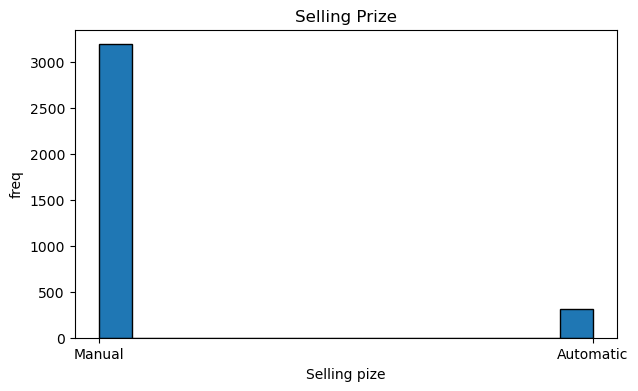

In [44]:
plt.figure(figsize = (7, 4))
plt.hist(df["transmission"], bins = 15, edgecolor = 'black')
plt.title("Selling Prize")
plt.xlabel("Selling pize")
plt.ylabel("freq")
plt.show()

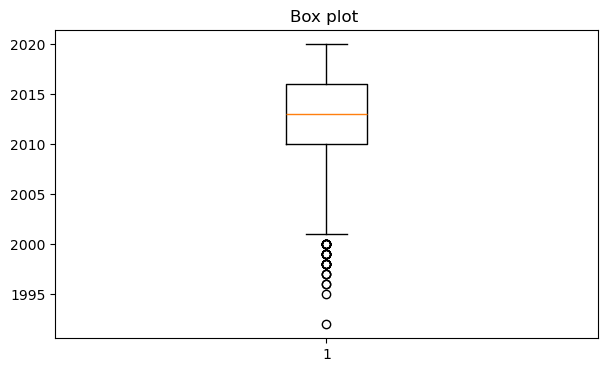

In [46]:
plt.figure(figsize=(7, 4))
plt.boxplot(df["year"])
plt.title("Box plot ")
plt.show()


In [47]:
df.head(2)

,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,2007,60000.0,70000.0,Petrol,Individual,Manual,First Owner
1,2007,135000.0,50000.0,Petrol,Individual,Manual,First Owner


In [62]:
df.shape

(3499, 7)

In [48]:
le = LabelEncoder()

In [49]:
df["fuel"] = le.fit_transform(df["fuel"])
df["seller_type"] = le.fit_transform(df["seller_type"])
df["transmission"] = le.fit_transform(df["transmission"])
df["owner"] = le.fit_transform(df["owner"])

In [50]:
df

,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,2007,60000.0,70000.0,4,1,1,0
1,2007,135000.0,50000.0,4,1,1,0
2,2012,600000.0,100000.0,1,1,1,0
3,2017,250000.0,46000.0,4,1,1,0
4,2014,450000.0,141000.0,1,1,1,2
...,...,...,...,...,...,...,...
4334,2012,600000.0,170000.0,1,1,1,0
4335,2014,409999.0,80000.0,1,1,1,2
4337,2009,110000.0,83000.0,4,1,1,2
4338,2016,865000.0,90000.0,1,1,1,0


In [51]:
X = df.drop("selling_price", axis = 1)
y = df["selling_price"]

In [55]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=46)

In [57]:
X_train.shape

(2799, 6)

In [58]:
y_train.shape

(2799,)

In [59]:
scaler = StandardScaler()

In [60]:
X_train_Scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [61]:
print("Encoded Dataset", df.shape)

Encoded Dataset (3499, 7)


In [63]:
df

,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,2007,60000.0,70000.0,4,1,1,0
1,2007,135000.0,50000.0,4,1,1,0
2,2012,600000.0,100000.0,1,1,1,0
3,2017,250000.0,46000.0,4,1,1,0
4,2014,450000.0,141000.0,1,1,1,2
...,...,...,...,...,...,...,...
4334,2012,600000.0,170000.0,1,1,1,0
4335,2014,409999.0,80000.0,1,1,1,2
4337,2009,110000.0,83000.0,4,1,1,2
4338,2016,865000.0,90000.0,1,1,1,0


In [67]:
print("\n Training Samples:", X_train_Scaled.shape)
print("\n Testing Samples:", X_test_scaled.shape)


 Training Samples: (2799, 6)

 Testing Samples: (700, 6)


In [85]:
ds = pd.read_csv("cafe.csv")

In [86]:
ds

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2,4,Credit Card,Takeaway,08-09-2023
1,TXN_4977031,Cake,4,3,12,Cash,In-store,16-05-2023
2,TXN_4271903,Cookie,4,1,ERROR,Credit Card,In-store,19-07-2023
3,TXN_7034554,Salad,2,5,10,UNKNOWN,UNKNOWN,27-04-2023
4,TXN_3160411,Coffee,2,2,4,Digital Wallet,In-store,11-06-2023
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2,2,4,NaN,UNKNOWN,30-08-2023
9996,TXN_9659401,NaN,3,NaN,3,Digital Wallet,NaN,02-06-2023
9997,TXN_5255387,Coffee,4,2,8,Digital Wallet,NaN,02-03-2023
9998,TXN_7695629,Cookie,3,NaN,3,Digital Wallet,NaN,02-12-2023


In [87]:
ds = ds.drop_duplicates()

In [88]:
ds.isnull().sum()

Transaction ID         0
Item                 334
Quantity             142
Price Per Unit       184
Total Spent          176
Payment Method      2579
Location            3267
Transaction Date     162
dtype: int64

In [89]:
ds = ds.drop(["Transaction ID", "Transaction Date"], axis = 1)

In [90]:
ds

,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location
0,Coffee,2,2,4,Credit Card,Takeaway
1,Cake,4,3,12,Cash,In-store
2,Cookie,4,1,ERROR,Credit Card,In-store
3,Salad,2,5,10,UNKNOWN,UNKNOWN
4,Coffee,2,2,4,Digital Wallet,In-store
...,...,...,...,...,...,...
9995,Coffee,2,2,4,NaN,UNKNOWN
9996,NaN,3,NaN,3,Digital Wallet,NaN
9997,Coffee,4,2,8,Digital Wallet,NaN
9998,Cookie,3,NaN,3,Digital Wallet,NaN


In [91]:
ds["Quantity"] = pd.to_numeric(ds["Quantity"], errors = "coerce")
ds["Price Per Unit"] = pd.to_numeric(ds["Price Per Unit"], errors = "coerce")
ds["Total Spent"] = pd.to_numeric(ds["Total Spent"], errors = "coerce")

In [95]:
ds["Quantity"] = ds["Quantity"].fillna(ds["Quantity"].median())
ds["Price Per Unit"] = ds["Price Per Unit"].fillna(ds["Price Per Unit"].median())
ds["Total Spent"] = ds["Total Spent"].fillna(ds["Total Spent"].median())
ds["Item"] = ds["Item"].fillna(ds["Item"].mode()[0])
ds["Payment Method"] = ds["Payment Method"].fillna(ds["Payment Method"].mode()[0])
ds["Location"] = ds["Location"].fillna(ds["Location"].mode()[0])

In [96]:
df

,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,2007,60000.0,70000.0,4,1,1,0
1,2007,135000.0,50000.0,4,1,1,0
2,2012,600000.0,100000.0,1,1,1,0
3,2017,250000.0,46000.0,4,1,1,0
4,2014,450000.0,141000.0,1,1,1,2
...,...,...,...,...,...,...,...
4334,2012,600000.0,170000.0,1,1,1,0
4335,2014,409999.0,80000.0,1,1,1,2
4337,2009,110000.0,83000.0,4,1,1,2
4338,2016,865000.0,90000.0,1,1,1,0
